In [19]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from tensorflow.keras.layers import Input
import pandas as pd


import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [4, 4]
plt.rcParams['font.size'] = 23
plt.rc('xtick', labelsize=23) 
plt.rc('ytick', labelsize=23)

In [2]:
# === CONFIGURATION ===
J_VALUE = "1.0"           # Exchange coupling
N_COMPONENTS = 500        # Number of PCA components
ETA_TRAIN = 0.05          # Training noise level
ETA_TEST  = 0.2          # Test noise level

In [3]:
# === DATA LOADING ===
def load_dataset(q_vectors, data_dir):

    conductance = []
    q_loaded = []   

    for i in range(len(q_vectors)):
        qx_val, qy_val = q_vectors[i]
        filename = f"q1_{qx_val:.4f}_q2_{qy_val:.4f}.csv"
        filepath = os.path.join(data_dir, filename)

        if not os.path.exists(filepath):
            #print(f"Missing file at index {i}: {filepath}")
            continue

        df = pd.read_csv(filepath)

        if df.empty or 'Conductance' not in df.columns or len(df) != 51 * 51:
            #print(f"Corrupted file at index {i}: {filepath}")
            continue

        # Reshape conductance values into 51x51 array (rows=flux, cols=mu)
        data_array = df['Conductance'].values.reshape((51, 51))

        # Apply the upper-triangular mask to utilize the symmetry of the samples
        flipped = np.fliplr(data_array.copy())
        mask = np.tril(np.ones_like(flipped, dtype=bool), k=-1)
        flipped[mask] = 0
        masked_array = np.fliplr(flipped)
        conductance.append(masked_array.flatten().tolist())
        q_loaded.append(q_vectors[i])

    X = np.array(conductance)

    #Filtering small components
    X[np.abs(X) < 1e-5] = 0.0

    return X, np.array(q_loaded)

In [4]:
# === DATASET PREPARATION ===
np.random.seed(42) 

q_vectors = np.loadtxt(f'Conductance_datasets/Full_Datasets/q_vectors_J({J_VALUE}).txt', comments='#')  # q_vectors read from file

X, y = load_dataset(q_vectors, f'Conductance_datasets/Full_Datasets/conductance_dataset_J({J_VALUE})')

In [5]:
# === HELPER FUNCTIONS ===

def add_noise(data, eta):
    noise = np.random.uniform(-eta, eta, size=data.shape)
    noisy_data = data*(1 + noise/2)**2 
    return noisy_data

def to_polar_coordinates(q_true_1, q_true_2 , q_pred_1, q_pred_2):
    
    #basis vectors
    b1 = [1/np.sqrt(3), 1]
    b2 = [-1/np.sqrt(3), 1]
    
    q_true_x = q_true_1*b1[0] + q_true_2*b2[0]
    q_true_y = q_true_1*b1[1] + q_true_2*b2[1]

    q_pred_x = q_pred_1*b1[0] + q_pred_2*b2[0]
    q_pred_y = q_pred_1*b1[1] + q_pred_2*b2[1]
    
    r_true = np.sqrt(q_true_x**2 + q_true_y**2)
    r_pred = np.sqrt(q_pred_x**2 + q_pred_y**2)
    
    eps = 10**-12
    maskN = (q_true_x**2 + q_true_y**2 > eps) & (q_pred_x**2 + q_pred_y**2 > eps)

    theta_true = np.arctan2(q_true_y[maskN], q_true_x[maskN])*180/(np.pi)
    theta_pred = np.arctan2(q_pred_y[maskN], q_pred_x[maskN])*180/(np.pi)
    
    return r_pred, r_true, theta_pred, theta_true

def to_cartesian_coordinates(q1, q2):
    b1 = [1/np.sqrt(3), 1]
    b2 = [-1/np.sqrt(3), 1]
    qx = q1 * b1[0] + q2 * b2[0]
    qy = q1 * b1[1] + q2 * b2[1]
    return qx, qy

def fidelity_theta(q_true_1, q_true_2 , q_pred_1, q_pred_2):
    
    q_true_x, q_true_y = to_cartesian_coordinates(q_true_1, q_true_2)
    q_pred_x, q_pred_y = to_cartesian_coordinates(q_pred_1, q_pred_2)
    
    r_true = np.sqrt(q_true_x**2 + q_true_y**2)
    r_pred = np.sqrt(q_pred_x**2 + q_pred_y**2)
    
    eps = 1e-12
    mask = (r_true > eps) & (r_pred > eps)

    qt_x = q_true_x[mask]
    qt_y = q_true_y[mask]
    qp_x = q_pred_x[mask]
    qp_y = q_pred_y[mask]
    
    dot = qt_x * qp_x + qt_y * qp_y
    norms = np.sqrt((qt_x**2 + qt_y**2) * (qp_x**2 + qp_y**2))
    return np.mean(2 * (dot / norms)**2 - 1)

def fidelity_q(q_true_1, q_true_2, q_pred_1, q_pred_2):
    
    q_true_1 = np.concatenate((q_true_1, -q_true_1), axis=0)
    q_true_2 = np.concatenate((q_true_2, -q_true_2), axis=0)
    q_pred_1 = np.concatenate((q_pred_1, -q_pred_1), axis=0)
    q_pred_2 = np.concatenate((q_pred_2, -q_pred_2), axis=0)
    
    q_true_x, q_true_y = to_cartesian_coordinates(q_true_1, q_true_2)
    q_pred_x, q_pred_y = to_cartesian_coordinates(q_pred_1, q_pred_2)
    
    true_values = np.sqrt(q_true_x**2 + q_true_y**2)
    predicted_values = np.sqrt(q_pred_x**2 + q_pred_y**2)
    
    num = np.mean(predicted_values*true_values)-np.mean(predicted_values,dtype=np.float64)*np.mean(true_values,dtype=np.float64)
    den = np.sqrt(np.var(true_values))*np.sqrt(np.var(predicted_values))
    f = np.abs(num)/den
    return f

In [6]:
# === NEURAL NETWORK MODEL ===
def train_model(n_components, eta_train, show_plots=True):

    # --- Split raw data ---
    X_train_rest, X_test_raw, y_train_rest, y_test_raw = train_test_split(X, y, test_size=0.2, shuffle=True, random_state=42)
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(X_train_rest, y_train_rest, test_size=0.15, shuffle=True, random_state=42)

    # --- Variance filter ---
    selector = VarianceThreshold(threshold=1e-6)

    X_train_filtered = selector.fit_transform(X_train_raw)
    X_val_filtered   = selector.transform(X_val_raw)
    X_test_filtered  = selector.transform(X_test_raw)

    # --- Add noise to training ---
    X_train_noisy = add_noise(X_train_filtered, eta_train)
    X_val_noisy   = add_noise(X_val_filtered, eta_train)

    # --- Scaling ---
    scaler_X = StandardScaler()

    X_train = scaler_X.fit_transform(X_train_noisy)
    X_val   = scaler_X.transform(X_val_noisy)

    scaler_y = StandardScaler()

    y_train_scaled = scaler_y.fit_transform(y_train)
    y_val_scaled   = scaler_y.transform(y_val)


    # --- PCA ---
    pca = PCA(n_components)

    train_pca = pca.fit_transform(X_train)
    val_pca   = pca.transform(X_val)
    

    # check the cumulative variance (it gives the idea of how much info is stored in the PCA components, so has to be high!!)
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

    if show_plots:
        plt.plot(cumulative_variance, color ='k', lw=3.5)
        plt.ylim(0.245, 1)
        plt.xlabel('Number of PCs')
        plt.ylabel('Cumulative variance')

        plt.show()
    

    # --- Model ---
    model = Sequential([
    Input(shape=(train_pca.shape[1],)),
    Dense(100, activation='relu'),
    Dense(100, activation='relu'),
    Dense(2)
    ])

    model.compile(optimizer=Adam(1e-3), loss='mse')

    history = model.fit(
        train_pca,
        y_train_scaled,
        epochs=100,
        batch_size=16,
        validation_data=(val_pca, y_val_scaled),
        verbose=0,
        shuffle=True
    )
    
    if show_plots:
        plt.plot(history.history['loss'], label='Train Loss')
        plt.plot(history.history['val_loss'], label='Validation Loss')
        plt.xlabel('Epoch')
        plt.ylabel('MSE Loss')
        plt.title('Training History', fontsize=20)

        plt.legend(fontsize=16, loc = 'upper center')

        plt.show()
    
    return model, scaler_X, scaler_y, pca, X_test_filtered, y_test_raw, selector

In [7]:
# === TESTING FUNCTION ===
def test_model(model, scaler_X, scaler_y, pca, X_test_filtered, y_test_raw, eta_test):

    # add test noise
    X_test_noisy = add_noise(X_test_filtered, eta_test)

    # scale
    X_test_scaled = scaler_X.transform(X_test_noisy)

    # PCA
    test_pca = pca.transform(X_test_scaled)

    # prediction
    q_pred = model.predict(test_pca, verbose=0)

    q_pred = scaler_y.inverse_transform(q_pred)
    q_true = y_test_raw

    F_r = fidelity_q(q_true[:,0], q_true[:,1], q_pred[:,0], q_pred[:,1])
    F_phi = fidelity_theta(q_true[:,0], q_true[:,1], q_pred[:,0], q_pred[:,1])

    return q_pred, q_true, F_r, F_phi

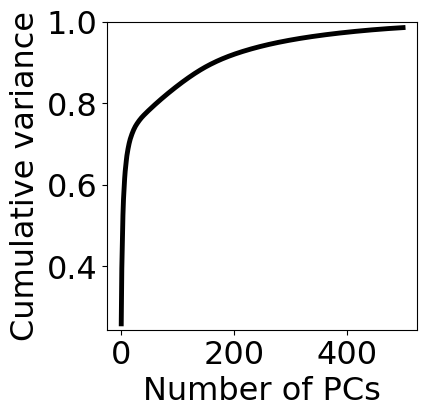

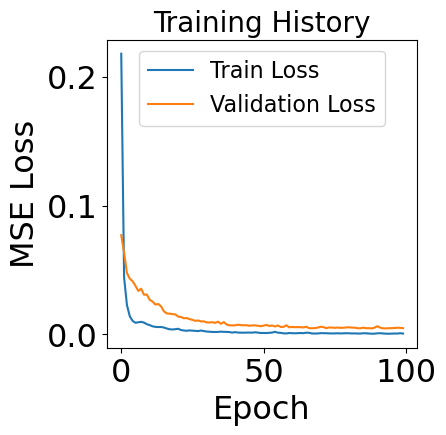

In [17]:
# === TESTING RUN ===
model, scaler_X, scaler_y, pca, X_test_filtered, y_test_raw, selector = train_model(N_COMPONENTS, ETA_TRAIN)

result = test_model(model, scaler_X, scaler_y, pca, X_test_filtered, y_test_raw, ETA_TEST)

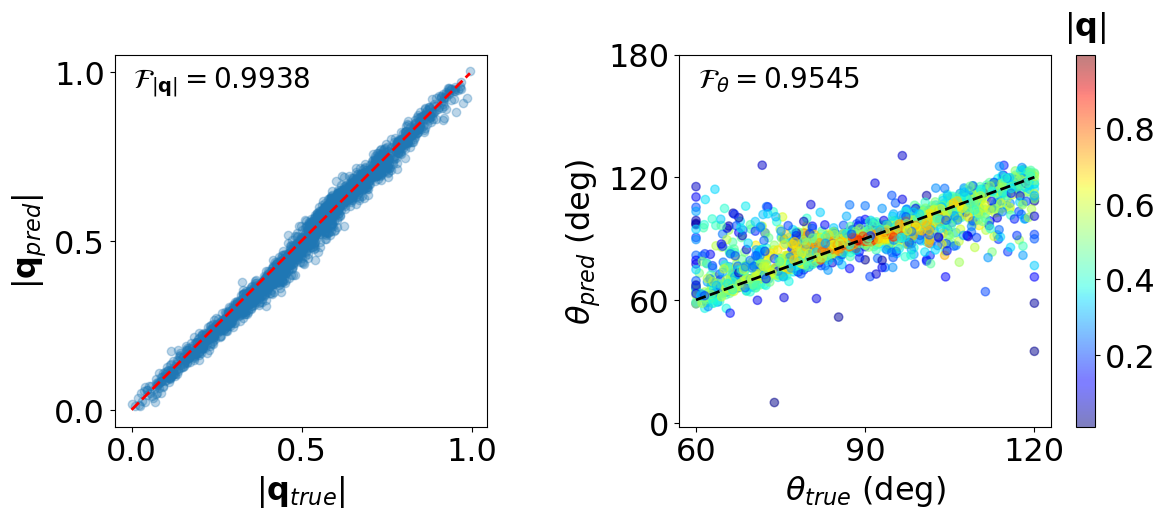

In [18]:
# === PREDICTIONS ===
r_pred, r_true, theta_pred, theta_true = to_polar_coordinates(result[1][:, 0], result[1][:, 1], result[0][:, 0], result[0][:, 1])
F_q, F_theta = result[2:]

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
eps = 10**-12


# --- Magnitude subplot ---

axs[0].scatter(r_true, r_pred, alpha=0.3)
axs[0].plot([min(r_true), max(r_true)],
            [min(r_true), max(r_true)], 'r--', lw=2)

axs[0].text(0.05, 0.975, rf'$\mathcal{{F}}_{{|\mathbf{{q}}|}} = {F_q:.4f}$',
            transform=axs[0].transAxes,
            fontsize=20, verticalalignment='top')

axs[0].set_yticks([0, 0.5, 1])

axs[0].set_xlabel(r'$|\mathbf{q}_{true}|$')
axs[0].set_ylabel(r'$|\mathbf{q}_{pred}|$')


axs[0].set_box_aspect(1)

# --- Angle subplot ---

sc = axs[1].scatter(theta_true, theta_pred, alpha=0.5, c=r_true[(r_true > eps) & (r_pred > eps)], cmap='jet')

axs[1].plot([min(theta_true), max(theta_true)],
            [min(theta_true), max(theta_true)], 'k--', lw=2)

axs[1].text(0.05, 0.975, rf'$\mathcal{{F}}_\theta = {F_theta:.4f}$',
            transform=axs[1].transAxes,
            fontsize=20, verticalalignment='top')

axs[1].set_xticks([60, 90, 120])
axs[1].set_yticks([0, 60, 120, 180])
axs[1].set_xlabel(r'$\theta_{true}$ (deg)')
axs[1].set_ylabel(r'$\theta_{pred}$ (deg)')
axs[1].set_box_aspect(1)
axs[1].set_ylim(-2, 180)


cbar = fig.colorbar(sc, ax=axs[1])
cbar.ax.set_xlabel(r'$|\mathbf{q}|$', labelpad=14)
cbar.ax.xaxis.set_label_position('top')  
cbar.ax.xaxis.set_ticks_position('top')  

cbar.set_ticks([0.2, 0.4, 0.6, 0.8])
cbar.set_ticklabels([0.2, 0.4, 0.6, 0.8])


fig.tight_layout(pad=0.001)
#fig.savefig('Prediction_results.png', dpi=600, bbox_inches='tight')
plt.show()